# 1.Importeren van libraries en datasets
Hier worden eerst alle relevante libraries ingelezen die gebruikt worden dataframes te bouwen en grafieken op te bouwen in het notebook.
Voor de datasets worden de parquet-bestanden uit de data analyse gebruikt. 
Deze datasets worden ook gebruikt in het PowerBI dashboard. Mochten er wijzigingen in de data pipeline plaatsvinden, worden deze direct verwerkt in alle grafieken en dashboards van beide rapportage vormen.
Deze werkwijze zorgt er ook voor dat onderlinge aansluiting gecontroleerd worden.
Er is ook te spreken van een single source of truth, gezien alle dashboards op dezelfde bronnen zijn gebaseerd.

In [71]:
#Importeren van libraries
import matplotlib.pyplot as plt
import pandas as pd
import squarify
import plotly.graph_objs as go
import plotly.io as pio
import dash
from dash import dcc, html
from dash.dependencies import Input, Output
import plotly.express as px
import numpy as np

In [72]:
#Importeren parquet files uit ETL.
#De parquet files bevatten een relatief pad tot de map waarin de python file staat.
sales_df = pd.read_parquet(r"PQ/Contoso_sales.parquet")
product_df = pd.read_parquet(r"PQ/Contoso_product.parquet")
calendar_df = pd.read_parquet(r"PQ/Contoso_calendar.parquet")
geography_df = pd.read_parquet(r"PQ/Contoso_geography.parquet")
stores_df = pd.read_parquet(r"PQ/Contoso_stores.parquet")
promotions_df = pd.read_parquet(r"PQ/Contoso_promotions.parquet")
productcat_df = pd.read_parquet(r"PQ/Contoso_productcat.parquet")
channel_df = pd.read_parquet(r"PQ/Contoso_channel.parquet")
GDP_df = pd.read_parquet(r"PQ/Contose_GDP.parquet")

# 2.Grafieken en dashboards
In dit onderdeel worden de verschillende grafieken uit PowerBI opgebouwd, voornamelijk met behulp van pandas, plotly en matplotlib.
Eerst worden deze individueel opgebouwd en zonder filters. Vervolgens worden ze met behulp van de Dash library verwerkt in een interactief dashboard dat de PowerBI functionaliteit zoveel mogelijk nabootst.
Gezien het doel van de opdracht niet is om PowerBI te vervangen, zijn niet alle functionaliteiten uit het PowerBI dashboard toegevoegd.
Drilldowns en knoppen om input te veranderen zijn hier buiten beschouwing gelaten.

## 2.1 Sales Dashboard

###  2.1.1 KPI's - GSM-01
In dit onderdeel worden de KPI kaarten gemaakt met behulp van plotly.
Eerst worden measures gemaakt voor de verschillende metingen, vervolgens worden deze omgezet in verschillende KPI's.
De output is een kaart die de cumulatieve waarde van de gehele dataset weergeeft, in het dash gedeelte wordt dit verder uitgewerkt tot een KPI met trends en ontwikkelingen in relatie tot voorgaand jaar.
Europese weergave van getallen vindt plaats in het dashboard.

In [73]:
#Measures
#In dit onderdeel worden de measures uit PowerBI nagemaakt. 
#De waarden voor revenue en cost worden eerst totaal berekend. Vervolgens worden Gross Margin en Gross margin in procenten op basis hiervan berekend.

#Revenue berekening
revenue = sales_df["SalesAmountRet"].sum()

#Cost berekening
total_cost = sales_df["TotalCostRet"].sum()

#Gross margin berekening
gross_margin = revenue - total_cost

#Gross margin in percentage
gross_margin_pct = (gross_margin / revenue)*100


In [74]:
#Revenue KPI
fig = go.Figure(
    #Maakt de figuur
    go.Indicator(
        #Maakt de KPI-visual
        mode="number",
        value=revenue,
        title={"text": "Revenue"},
        number={
            #Zet euro-teken voor het getal
            "prefix": "€",
            #Rond af op 0 decimalen. 
            "valueformat": ",.0f" 
        }
    )
)
fig.update_layout(
    height=200,
    width=300
)
#Formaat instellen
fig.show()

In [75]:
#Cost KPI
fig = go.Figure(
    #Maakt de figuur
    go.Indicator(
        #Maakt de KPI-visual
        mode="number",
        value=total_cost,
        title={"text": "Cost"},
        number={
            "prefix": "€",
            #Zet euro-teken voor het getal
            "valueformat": ",.0f"
            #Rond af op hele getallen en gebruikt komma's als scheidingstekens tussen duizendtallen.
        }
    )
)
fig.update_layout(
    height=200,
    width=300
)
#Formaat instellen
fig.show()


In [76]:
#Gross margin KPI
fig = go.Figure(
    #Maakt de figuur
    go.Indicator(
        #Maakt de KPI-visual
        mode="number",
        value=gross_margin,
        title={"text": "Gross Margin"},
        number={
            "prefix": "€",
            #Zet euro-teken voor het getal
            "valueformat": ",.0f"
            #Rond af op hele getallen en gebruikt komma's als scheidingstekens tussen duizendtallen.
        }
    )
)
fig.update_layout(
    height=200,
    width=300
)
#Formaat instellen
fig.show()


In [77]:
#Gross margin percentage KPI
fig = go.Figure(
    #Maakt de figuur
    go.Indicator(
        #Maakt de KPI-visual
        mode="number",
        value=gross_margin_pct,
        title={"text": "Gross Margin percentage"},
        number={
            "suffix": "%",
            # %-teken na het percentage.
            "valueformat": ".01f"
            #Rond het percentage af op 1 decimaal.

        }
    )
)
fig.update_layout(
    height=200,
    width=300
)
#Formaat instellen

fig.show()


### 2.1.2 Revenue over time - GSM-02
In dit onderdeel wordt de linechart gemaakt die omzetontwikkeling per jaar vergelijkt, met behulp van Plotly.
Knoppen om te wisselen tussen revenue, cost, en gross margin zijn hier buiten de chart gelaten. 
Dit zou enkel het presenteren van andere waarden in dezelfde chart betreffen en weinig extra waarde toevoegen voor het doeleinde van de opdracht.

In [78]:
#Dataframe

#Totale omzet aggregeren per maand en reset de index, zodat datum niet als index gebruikt blijft worden
monthly_revenue = sales_df.resample("ME", on="Date").agg(Revenue=("SalesAmountRet","sum")).reset_index()

#Maakt een kolom met de dataframe in jaar.
monthly_revenue["Year"] = monthly_revenue["Date"].dt.year.astype(str)

#Maakt een kolom met de maand van het jaar in nummers.
monthly_revenue["Month"] = monthly_revenue["Date"].dt.month

In [79]:
#Chart

#Figuur maken met maanden op de x-as, omzet op de y-as en aparte lijnen voor ieder jaar.
fig = px.line(
    monthly_revenue,
    x="Month",
    y="Revenue",
    color="Year",
    title="Revenue over time"
)

#Omschrijvingen van assen toevoegen.
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Revenue",
    height=400,
    width=1000
)

#Valuta maken van waarden op de y-as
fig.update_yaxes(
    tickprefix="€",
    tickformat=",.0f"
)

#Nummers omzetten in afkortingen van maanden.
fig.update_xaxes(
    tickmode="array",
    tickvals=list(range(1, 13)),
    ticktext=[
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

fig.show()

### 2.1.3 Revenue by channel - GSM-04
In dit onderdeel wordt de horizontal bar chart gemaakt die omzet per channel vergelijkt tussen jaren, met behulp van Plotly.

In [80]:
#Dataframe

#Aparte Dataframe maken waarbij Channel wordt gemerged met de salesdataset.
channel_sales = sales_df.merge(right=channel_df, on="ChannelKey", how="left", indicator=True)

#Dataframe aggregeren op relevante attributen.
channel_revenue = (
    channel_sales
    .groupby("ChannelName", as_index=False)
    .agg(Revenue=("SalesAmountRet", "sum"))
    .sort_values("Revenue", ascending=True)
)

In [81]:
#Chart

#Bar chart maken met behulp van channel_revenue dataframe.
fig = px.bar(
    channel_revenue,
    x="Revenue",
    y="ChannelName",
    orientation="h",
    title="Revenue by sales channel"
)

#Layout van chart aanpassen.
fig.update_layout(
    #Titels voor axes instellen.
    xaxis_title="Revenue",
    yaxis_title="Sales channel",

    #Hoogte en wijdte van de chart instellen.
    height=400,
    width = 800
)

#Weergave van waarden op de x-as aanpassen.
fig.update_xaxes(
    tickprefix="€",
    tickformat=",.0f"
)

fig.show()

### 2.1.4 Revenue by product category - GSM-05
In dit onderdeel wordt de donutchart gemaakt die het aandeel van productgroepen in omzet laat zien, met behulp van Plotly.

In [82]:
#Dataframe

#Sales data mergen met product en product categorieën.
product_sales = (
    sales_df
    .merge(
        product_df,
        on="ProductKey",
        #Left join toegepast, gezien we alle waarden uit de sales data willen behouden onafhankelijk of deze wel of niet matcht op een waarde in product_df. 
        #Een inner join zou ook voldoende zijn, gezien in de data analyse al is vastgesteld dat er voor alle ProductKeys in de sales data een waarde in de product dataset voorkomt.
        how="left",
        indicator=True
    )
    .merge(
        productcat_df,
        on="ProductSubcategoryKey", 
        how="left",
    )
)

#Dataframe aggregeren op relevante informatie.
category_revenue = (
    product_sales
    .groupby("ProductCategory", as_index=False)
    .agg(Revenue=("SalesAmountRet", "sum"))
    .sort_values("Revenue", ascending=True)
)

In [83]:
#Chart

#Pie chart maken.
fig = px.pie(
    category_revenue,
    values="Revenue",
    names="ProductCategory",
    #Zonder hole eigenschap wordt dit een normale pie chart.
    hole=0.8,
    title="Revenue by product category"
)

#Dimensies van grafiek bepalen.
fig.update_layout(
    height=450,
    width=800
)

#Toelichting van de waarden weergeven in de grafiek.
fig.update_traces(
    textposition="outside",
    textinfo="percent+label",
    showlegend=False
    
)

fig.show()

### 2.1.5 GDP per capita versus revenue - GSM-03
In dit onderdeel wordt de scatterchart gemaakt de correlatie tussen revenue en GDP per jaar meet, met behulp van Plotly.

In [84]:
#Dataframe

#Sales data mergen met geography gegevens
sales_geo = sales_df.merge(
    geography_df,
    on="GeographyKey",
    how="left"
)

sales_geo["Year"] = sales_geo["Date"].dt.year

#GDP data toevoegen aan eerdere sales_geo dataframe.
sales_gdp = sales_geo.merge(
    GDP_df,
    left_on=["RegionCountryName","Year"],
    right_on=["CountryKey","Year"],  
    how="left"
)

#Dataframe maken die per landnaam en jaar omzet, kosten en GDP aggregeert.
country_year = (
    sales_gdp
    .groupby(["RegionCountryName", "Year"], as_index=False)
    .agg(
        Revenue=("SalesAmountRet", "sum"),
        TotalCost=("TotalCostRet", "sum"),
        GDP_per_capita=("GDPPerCapita", "mean")
    )
)

#Gross margin waarde toevoegen aan dataframe.
country_year["GrossMargin"] = (
    country_year["Revenue"] - country_year["TotalCost"]
)

#Year omzetten naar string, anders wordt deze als numerieke waarden geïnterpreteerd door Plotly
country_year["Year"] = country_year["Year"].astype(str)


In [85]:
#Chart

#Scatter chart maken
fig = px.scatter(
    country_year,
    #Horziontale as is het GDP per capita
    x="GDP_per_capita",
    #Y as is de omzet
    y="Revenue",
    #Waarden in de scatterplot, de jaren
    color="Year",
    #De waarden zijn de landen
    hover_name="RegionCountryName",
    title="Revenue vs GDP per capita",
    #Bubbel size afhankelijk maken van de grossmargin.
    #Hoe beter de Gross Margin hoe groter de bubbel.
    size="GrossMargin"
)

#Titels en dimensies van grafiek bepalen.
fig.update_layout(
    xaxis_title="GDP per capita",
    yaxis_title="Revenue",
    height=450,
    width=1000,
)

fig.update_yaxes(
    tickprefix="€",
    tickformat=",.0f"
)

fig.show()


### 2.1.6 Dashboard
Met behulp van voorgaande grafieken wordt een dashboard opgesteld met behulp van de dash library.

In [86]:
#Slicers

#Year slicer
year_options = sorted(sales_df["Date"].dt.year.unique())
year_dropdown = dcc.Dropdown(
id="year-filter",
#Id van het component
options=[
    {"label": str(year), "value": year}
    for year in year_options
],
#Maken van een dictionairy met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
placeholder="Select year",
#Tekst die weergegeven wordt als er niks geselecteerd is.
multi=True
#Staat toe dat er meerdere waarden worden geselecteerd.
)
year_options

[np.int32(2011), np.int32(2012), np.int32(2013)]

In [87]:
#Sicer testen
app = dash.Dash(__name__)

app.layout = html.Div([
    html.H2("Sales Dashboard"),

    year_dropdown,

    dcc.Graph(
        id="revenue-over-time"
    )
])

app.run(debug=True)

In [88]:
#Eerste dashboard versie

#Dashboard initiliaseren.
app = dash.Dash(__name__)

#Layout van dashboard.
app.layout = html.Div([
    html.H2("Sales Dashboard"),

    year_dropdown,

    dcc.Graph(
        id="revenue-over-time"
    )
])


@app.callback(
    #Output betreft charts, input betreft slicers.
    Output("revenue-over-time", "figure"),
    Input("year-filter", "value")
)
def update_revenue_chart(selected_years):
    df = sales_df.copy()

    #If-statement die grafiek aanpast op basis van slicer input.
    if selected_years:
        df = df[df["Date"].dt.year.isin(selected_years)]

    monthly_revenue = (
        df
        .resample("ME", on="Date")
        .agg(Revenue=("SalesAmountRet", "sum"))
        .reset_index()
    )

    monthly_revenue["Year"] = monthly_revenue["Date"].dt.year.astype(str)
    monthly_revenue["Month"] = monthly_revenue["Date"].dt.month

    #Linechart op basis van eerder gecreeërde line chart.
    fig = px.line(
        monthly_revenue,
        x="Month",
        y="Revenue",
        color="Year",
        title="Revenue over time"
    )

    fig.update_layout(
        height=400,
        width=1000
    )
    fig.update_yaxes(
    tickprefix="€",
    tickformat=",.0f"
    )
    #Valuta maken van waarden op de y-as

    fig.update_xaxes(
    tickmode="array",
    tickvals=list(range(1, 13)),
    ticktext=[
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
    )

    return fig

app.run(debug=True)

In [89]:
#Dataqframe

#Opbouwen van dataframe voor het salesdashboard
#Eerst gebruikte dimensies mergen, channel, product, productsubcategory en geography.
sales_dashboard_df = (
    sales_df
    .merge(
        channel_df,
        on="ChannelKey",
        how="left"
    )
    .merge(
        product_df,
        on="ProductKey",
        how="left"
    )
    .merge(
        productcat_df,
        on="ProductSubcategoryKey",
        how="left"
    )
    .merge(
        geography_df,
        on="GeographyKey",
        how="left"
    )
)

sales_dashboard_df["Year"] = sales_dashboard_df["Date"].dt.year

#GDP landen per jaar mergen met eerdere gecreeërd salesdashboard.
#RegionCountryName is gelijk aan de CountryKey.
sales_dashboard_df = sales_dashboard_df.merge(
    GDP_df,
    left_on=["RegionCountryName", "Year"],
    right_on=["CountryKey", "Year"],
    how="left"
)

In [90]:
#Slicers opbouwen

#Year slicer
#Variabele maken met alle unieke jaartallen.
year_options = sorted(sales_dashboard_df["Date"].dt.year.unique())

year_dropdown = dcc.Dropdown(
#Id van het component
id="year-filter",
#Maken van een dictionary met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
options=[
    {"label": str(year), "value": year}
    for year in year_options
],
#Tekst die weergegeven wordt als er niks geselecteerd is.
placeholder="Select year",

#Staat toe dat er meerdere waarden worden geselecteerd.
multi=True
)

#Month Slicer
month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

month_options = sorted(sales_dashboard_df["Date"].dt.month.unique())
#Variabele maken met alle unieke maanden.

month_dropdown = dcc.Dropdown(
    #Id van het component
    id="month-filter",
    #Maken van een dictionary met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
    options=[
    {"label": month_names[month -1], "value": int(month)}
    for month in month_options
],

#Tekst die weergegeven wordt als er niks geselecteerd is.
placeholder="Select month(s)",

#Staat toe dat er meerdere waarden worden geselecteerd.
multi=True
)

#Countryname slicer
#Variabele maken met alle unieke landnamen.
country_options = sales_dashboard_df["RegionCountryName"].unique()

country_dropdown = dcc.Dropdown(
 #Id van het component
id="country-filter",
#Maken van een dictionary met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
options=[
    {"label": country, "value": country}
    for country in country_options
],
#Tekst die weergegeven wordt als er niks geselecteerd is.
placeholder="Select countries",
#Staat toe dat er meerdere waarden worden geselecteerd.
multi=True
)

country_dropdown = dcc.Dropdown(
id="country-filter",
#Id van het component
options=[
    {"label": country, "value": country}
    for country in country_options
],
#Maken van een dictionairy met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
placeholder="Select countries",
#Tekst die weergegeven wordt als er niks geselecteerd is.
multi=True
#Staat toe dat er meerdere waarden worden geselecteerd.
)

#Continent slicer
continent_options = sales_dashboard_df["ContinentName"].dropna().unique()

continent_list = dcc.Checklist(
#Id van het component
id="continent-filter",
#Maken van een dictionary met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
options=[
    {"label": continent,"value": continent}
    for continent in continent_options
],

#Staat toe dat er meerdere waarden worden geselecteerd.
value=[]
)

#Channel slicer
channel_options = sales_dashboard_df["ChannelName"].unique()

channel_list = dcc.Checklist(
#Id van het component
id="channel-filter",
#Maken van een dictionary met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
options=[
    {"label": channel,"value": channel}
    for channel in channel_options
],

#Staat toe dat er meerdere waarden worden geselecteerd.
value=[]
)

#Product category slicer
productcategory_options = sales_dashboard_df["ProductCategory"].unique()

productcategory_list = dcc.Checklist(
#Id van het component
id="productcategory-filter",
#Maken van een dictionary met labels en waarden. De labels worden weergegeven in het dashboard, de waarden zijn te gebruiken in de functie.
options=[
    {"label": productcategory,"value": productcategory}
    for productcategory in productcategory_options
],

#Staat toe dat er meerdere waarden worden geselecteerd.
value=[]

)


In [91]:
#Dashboard code
#App initialiseren
salesdashboard = dash.Dash(__name__)
# Layout 
salesdashboard.layout = html.Div([
    # Titel
    html.H2("Sales Dashboard",
            style={
                "textAlign":"center",
                "backgroundColor":"white",
                "margin": "0",
                "padding":"20px",
                "width":"100%",
                "boxSizing":"border-box",
                "fontSize":"32px"

            }),
    # Hoofdindeling: filters links, dashboard rechts
    html.Div([
        # Linkerkolom: filters
        html.Div([
            html.H4("Filters"),
            html.Label("Year"),
            year_dropdown,
            html.Label("Month"),
            month_dropdown,
            html.Label("Countries"),
            country_dropdown,
            html.Label("Continent"),
            continent_list,
            html.Label("Channel"),
            channel_list,
            html.Label("Product category"),
            productcategory_list
        ],
        style={
            "width": "15%",
            "padding": "20px",
            "background": "white",
            "boxSizing": "border-box"
        }),
        # Rechterkolom: dashboard
        html.Div([
            # KPI-rij
            html.Div([
                html.Div(
                    dcc.Graph(
                        id="revenue-kpi",
                        style={
                            "width": "100%",
                            "height": "250px"
                        }
                    ),
                    style={
                        "flex": "1 1 0",
                        "minWidth": "0"
                    }
                ),
                html.Div(
                    dcc.Graph(
                        id="cost-kpi",
                        style={
                            "width": "100%",
                            "height": "250px"
                        }
                    ),
                    style={
                        "flex": "1 1 0",
                        "minWidth": "0"
                    }
                ),
                html.Div(
                    dcc.Graph(
                        id="gross-margin-kpi",
                        style={
                            "width": "100%",
                            "height": "250px"
                        }
                    ),
                    style={
                        "flex": "1 1 0",
                        "minWidth": "0"
                    }
                ),
                html.Div(
                    dcc.Graph(
                        id="gross-margin-pct-kpi",
                        style={
                            "width": "100%",
                            "height": "250px"
                        }
                    ),
                    style={
                        "flex": "1 1 0",
                        "minWidth": "0"
                    }
                )
            ],
            style={
                "display": "flex",
                "width": "100%",
                "alignItems": "stretch"
            }),
            # Eerste grafiekrij
            html.Div([
                html.Div(
                    dcc.Graph(
                        id="revenue-over-time",
                        responsive=True,
                        style={"width": "100%"}
                    ),
                    style={
                        "flex": "1",
                        "minWidth": "0"
                    }
                ),
                html.Div(
                    dcc.Graph(
                        id="revenue-by-channel",
                        responsive=True,
                        style={"width": "100%"}
                    ),
                    style={
                        "flex": "1",
                        "minWidth": "0"
                    }
                )
            ],
            style={
                "display": "flex",
                "width": "100%",
            }),
            # Tweede grafiekrij
            html.Div([
                html.Div(
                    dcc.Graph(
                        id="revenue-by-product-category",
                        responsive=True,
                        style={"width": "100%"}
                    ),
                    style={
                        "flex": "1",
                        "minWidth": "0"
                    }
                ),
                html.Div(
                    dcc.Graph(
                        id="gdp-per-capita",
                        responsive=True,
                        style={"width": "100%"}
                    ),
                    style={
                        "flex": "1",
                        "minWidth": "0"
                    }
                )
            ],
            style={
                "display": "flex",
                "width": "100%",
            })
        ],
        style={
            "width": "85%",
            "boxSizing": "border-box"
        })
    ],
    style={
        "display": "flex",
        "width": "100%"
    })
])
@salesdashboard.callback(
    #Output betreft charts, input betreft waarden van slicers.
    Output("revenue-kpi", "figure"),
    Output("cost-kpi", "figure"),
    Output("gross-margin-kpi","figure"),
    Output("gross-margin-pct-kpi","figure"),
    Output("revenue-over-time","figure"),
    Output("revenue-by-channel","figure"),
    Output("revenue-by-product-category","figure"),
    Output("gdp-per-capita","figure"),
    Input("year-filter", "value"),
    Input("month-filter", "value"),
    Input("country-filter", "value"),
    Input("continent-filter", "value"),
    Input("channel-filter", "value"),
    Input("productcategory-filter", "value")
)
#functie die dashboard update a.d.h.v. input filters
def update_dashboard(selected_years, 
                     selected_months, 
                     selected_countries, 
                     selected_contintens, 
                     selected_channels, 
                     selected_productcategory):
    #Kopie van dataframe maken om te interpreteren
    df_base = sales_dashboard_df.copy()
    # Filters die dashboard filteren op waarden van de geselecterde filter.
    if selected_months:
        df_base = df_base[
            df_base["Date"].dt.month.isin(selected_months)
        ]
    if selected_countries:
        df_base = df_base[
            df_base["RegionCountryName"].isin(selected_countries)
        ]
    if selected_contintens:
        df_base = df_base[
            df_base["ContinentName"].isin(selected_contintens)
        ]
    if selected_channels:
        df_base = df_base[
            df_base["ChannelName"].isin(selected_channels)
        ]
    if selected_productcategory:
        df_base = df_base[
            df_base["ProductCategory"].isin(selected_productcategory)
        ]
    if selected_years:
        df = df_base[
         df_base["Year"].isin(selected_years)
    ]
    else:
        df = df_base
    # Meest recente jaar voor KPI bepalen
    if selected_years:
        current_year = max(selected_years)
    else:
        current_year = df_base["Year"].max()
    # Voorgaand jaar
    previous_year = current_year - 1
    # Data voor huidige jaar
    df_kpi_current = df_base[
        df_base["Year"] == current_year
    ]
    # Data voor voorgaand jaar
    df_kpi_previous = df_base[
        df_base["Year"] == previous_year
    ]
    # Controleren of het voorgaande jaar vergelijkingsgegevens bevat
    has_previous_year = not df_kpi_previous.empty

    # Revenue KPI-waarden
    revenue_current = df_kpi_current["SalesAmountRet"].sum()
    revenue_previous = df_kpi_previous["SalesAmountRet"].sum()
    cost_current = df_kpi_current["TotalCostRet"].sum()
    cost_previous = df_kpi_previous["TotalCostRet"].sum()
    grossmargin_current = revenue_current - cost_current
    grossmargin_previous = revenue_previous - cost_previous

    # Brutomargepercentage alleen berekenen als omzet niet nul is
    grossmarginpct_current = (grossmargin_current / revenue_current) * 100 if revenue_current != 0 else None
    grossmarginpct_previous = (grossmargin_previous / revenue_previous) * 100 if revenue_previous != 0 else None

    #Variabelen, gelijk aan measures in PowerBI.
    #Huidig jaar
    revenue = df["SalesAmountRet"].sum()
    total_cost = df["TotalCostRet"].sum()
    grossmargin = revenue-total_cost
    # Voorkomen dat bij een lege filterselectie door nul wordt gedeeld
    grossmarginpct = (grossmargin / revenue) * 100 if revenue != 0 else None
    #Aggregatie voor revenue over time.
    monthly_revenue = (
    df
    .resample("ME", on="Date")
    .agg(Revenue=("SalesAmountRet", "sum"))
    .reset_index()
    )

    #Jaar kolom toevoegen op basis van de date waarde in de monthly_revenuedataframe
    monthly_revenue["Year"] = monthly_revenue["Date"].dt.year.astype(str)
    monthly_revenue["Month"] = monthly_revenue["Date"].dt.month

    #Aggregatie voor revenue by channel
    channel_revenue= (df
    .groupby("ChannelName", as_index=False)
    .agg(Revenue=("SalesAmountRet", "sum"))
    .sort_values("Revenue", ascending=True)
    )

    #Aggregatie voor revenue by productcategory
    category_revenue = (
    df
    .groupby("ProductCategory", as_index=False)
    .agg(Revenue=("SalesAmountRet", "sum"))
    .sort_values("Revenue", ascending=True)
    )

    #Aggregatie voor gpd per capita versus revenue
    country_year = (
    df
    .groupby(["RegionCountryName", "Year"], as_index=False)
    .agg(
        Revenue=("SalesAmountRet", "sum"),
        TotalCost=("TotalCostRet", "sum"),
        GDP_per_capita=("GDPPerCapita", "mean")
        )
    )
    country_year["Year"] = country_year["Year"].astype(str)
    country_year["GrossMargin"] = (
    country_year["Revenue"] - country_year["TotalCost"]
    )

    #Europese formatering van decimale getallen en duizendtallen.
    def format_million(value):
        text = f"{value / 1_000_000:,.1f}"
        text = text.replace(",", "X").replace(".", ",").replace("X", ".")
        return f"{text}M"
    
    # Functie om procentuele afwijkingen veilig te berekenen
    # Bij ontbrekende gegevens of nul als vergelijkingswaarde is geen percentage beschikbaar
    def safe_pct(current, previous):
        if not has_previous_year or previous == 0:
            return None
        return ((current - previous) / previous) * 100

    
    # Procentuele afwijking formatteren met Europese decimaalnotatie
    def format_delta(value, decimals=2, suffix="%"):
        if value is None:
            return "N/A"
        return f"{value:+.{decimals}f}{suffix}".replace(".", ",")
    
    #KPI voor revenue
    # Procentuele afwijking t.o.v. vorig jaar
    delta_pct = safe_pct(revenue_current, revenue_previous)
    delta_text = format_delta(delta_pct)

    # Neutrale kleur bij ontbrekende vergelijkingsgegevens
    indicator_color = "gray" if delta_pct is None else ("green" if delta_pct >= 0 else "crimson")
    KPIrevenue = go.Figure()

    # Titel
    KPIrevenue.add_annotation(
        text="Revenue",
        x=0.5,
        y=0.88,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 22}
    )
    # Current year revenue
    KPIrevenue.add_annotation(
        text=format_million(revenue_current),
        x=0.5,
        y=0.64,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 30,
              "color": indicator_color}
    )
    # Previous year revenue
    KPIrevenue.add_annotation(
        text=f"Previous year: {format_million(revenue_previous) if has_previous_year else 'N/A'}",
        x=0.5,
        y=0.43,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17}
    )
    # Percentage verschil
    KPIrevenue.add_annotation(
        text=f"({delta_text})",
        x=0.5,
        y=0.29,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17,
              "color": indicator_color}
    )
    # Current year
    KPIrevenue.add_annotation(
        text=f"<b>Current year: {current_year}</b>",
        x=0.5,
        y=0.13,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 18}
    )
    KPIrevenue.update_layout(
        template="plotly_white",
        height=300,
        xaxis={"visible": False},
        yaxis={"visible": False}
    )
    #KPI voor kosten
    # Procentuele afwijking t.o.v. vorig jaar
    delta_cost_pct = safe_pct(cost_current, cost_previous)
    delta_text = format_delta(delta_cost_pct)
    # Bij kosten is een daling positief
    indicator_color = "gray" if delta_cost_pct is None else ("crimson" if delta_cost_pct >= 0 else "green")
    KPIcost = go.Figure()
    # Titel
    KPIcost.add_annotation(
        text="Cost",
        x=0.5,
        y=0.88,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 22}
    )
    # Current year cost
    KPIcost.add_annotation(
        text=format_million(cost_current),
        x=0.5,
        y=0.64,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 30,
              "color": indicator_color}
    )
    # Previous year cost
    KPIcost.add_annotation(
        text=f"Previous year: {format_million(cost_previous) if has_previous_year else 'N/A'}",
        x=0.5,
        y=0.43,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17}
    )
    # Percentage difference
    KPIcost.add_annotation(
        text=f"({delta_text})",
        x=0.5,
        y=0.29,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17,
              "color": indicator_color}
    )
    # Current year
    KPIcost.add_annotation(
        text=f"<b>Current year: {current_year}</b>",
        x=0.5,
        y=0.13,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 18}
    )
    KPIcost.update_layout(
        template="plotly_white",
        height=300,
        xaxis={"visible": False},
        yaxis={"visible": False}
    )
    #KPI voor grossmargin
    # Procentuele afwijking t.o.v. vorig jaar
    delta_grossmargin_pct = safe_pct(grossmargin_current, grossmargin_previous)
    delta_text = format_delta(delta_grossmargin_pct)
    indicator_color = "gray" if delta_grossmargin_pct is None else ("green" if delta_grossmargin_pct >= 0 else "crimson")
    KPIgrossmargin = go.Figure()
    # Titel
    KPIgrossmargin.add_annotation(
        text="Gross margin",
        x=0.5,
        y=0.88,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 22}
    )
    # Current year cost
    KPIgrossmargin.add_annotation(
        text=format_million(grossmargin_current),
        x=0.5,
        y=0.64,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 30,
              "color": indicator_color}
    )
    # Previous year cost
    KPIgrossmargin.add_annotation(
        text=f"Previous year: {format_million(grossmargin_previous) if has_previous_year else 'N/A'}",
        x=0.5,
        y=0.43,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17}
    )
    # Percentage difference
    KPIgrossmargin.add_annotation(
        text=f"({delta_text})",
        x=0.5,
        y=0.29,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17,
              "color": indicator_color}
    )
    # Current year
    KPIgrossmargin.add_annotation(
        text=f"<b>Current year: {current_year}</b>",
        x=0.5,
        y=0.13,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 18}
    )
    KPIgrossmargin.update_layout(
        template="plotly_white",
        height=300,
        xaxis={"visible": False},
        yaxis={"visible": False}
    )
    #KPI voor grossmarginpct
    # Procentuele afwijking t.o.v. vorig jaar
    # Verschil in brutomargepercentage wordt uitgedrukt in procentpunten
    delta_grossmarginpct_pct = (
        grossmarginpct_current - grossmarginpct_previous
        if grossmarginpct_current is not None and grossmarginpct_previous is not None
        else None
    )
    indicator_color = "gray" if delta_grossmarginpct_pct is None else ("green" if delta_grossmarginpct_pct >= 0 else "crimson")
    KPIgrossmarginpct = go.Figure()
    # Titel
    KPIgrossmarginpct.add_annotation(
        text="Gross margin %",
        x=0.5,
        y=0.88,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 22}
    )
    # Current year grossmargin percentage
    KPIgrossmarginpct.add_annotation(
        text=f"{grossmarginpct_current:.1f}%".replace(".", ",") if grossmarginpct_current is not None else "N/A",
        x=0.5,
        y=0.64,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 30,
              "color": indicator_color}
    )
    # Previous year grossmargin percentage
    KPIgrossmarginpct.add_annotation(
        text=f"Previous year: {grossmarginpct_previous:.1f}%".replace(".", ",") if grossmarginpct_previous is not None else "Previous year: N/A",
        x=0.5,
        y=0.43,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17}
    )
    # Percentage difference
    KPIgrossmarginpct.add_annotation(
        text=f"({format_delta(delta_grossmarginpct_pct, decimals=1, suffix='%')})",
        x=0.5,
        y=0.29,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 17,
              "color": indicator_color}
    )
    # Current year
    KPIgrossmarginpct.add_annotation(
        text=f"<b>Current year: {current_year}</b>",
        x=0.5,
        y=0.13,
        xref="paper",
        yref="paper",
        xanchor="center",
        yanchor="middle",
        showarrow=False,
        font={"size": 18}
    )
    KPIgrossmarginpct.update_layout(
        template="plotly_white",
        height=300,
        xaxis={"visible": False},
        yaxis={"visible": False}
    )

    #Opbouwen van de linechart met behulp van plotly en de monthly_revenue dataframe.
    RevenueOverTimeLine = px.line(
        monthly_revenue,
        x="Month",
        y="Revenue",
        color="Year",
        title="Revenue over time"
    )
    RevenueOverTimeLine.update_layout(
        height=400,
        width=1000
    )
    RevenueOverTimeLine.update_yaxes(
        tickprefix="€",
        tickformat=",.0f"
    )
    RevenueOverTimeLine.update_xaxes(
        tickmode="array",
        tickvals=list(range(1, 13)),
        ticktext=[
            "Jan", "Feb", "Mar", "Apr",
            "May", "Jun", "Jul", "Aug",
            "Sep", "Oct", "Nov", "Dec"
        ]
    )
    #Opbouwen van barchart met behulp van plotly en de channel_revenue dataframe.
    RevenueByChannelBar = px.bar(
    channel_revenue,
    x="Revenue",
    y="ChannelName",
    orientation="h",
    title="Revenue by sales channel"
    )
    RevenueByChannelBar.update_layout(
    xaxis_title="Revenue",
    yaxis_title="Sales channel",
    height=400,
    width = 800
    )
    #Titels voor axes instellen.
    #Hoogte en wijdte van de chart instellen.
    RevenueByChannelBar.update_xaxes(
    tickprefix="€",
    tickformat=",.0f"
    )
    #Opbouwen van donutchart met behulp van plotly en de categery_revenue dataframe.
    RevenueByProductCategory = px.pie(
    category_revenue,
    values="Revenue",
    names="ProductCategory",
    hole=0.8,
    title="Revenue by product category"
    )
    RevenueByProductCategory.update_layout(
    height=450,
    width=800
    )
    RevenueByProductCategory.update_traces(
    textposition="outside",
    textinfo="percent+label",
    showlegend=False
    )
    #Opbouwen van scattechart met behulp van plotly en de country_year dataframe.
    GDPPerCapita = px.scatter(
    country_year,
    x="GDP_per_capita",
    #Horziontale as is het GDP per capita
    y="Revenue",
    #Y as is de omzet
    color="Year",
    #Waarden in de scatterplot, de jaren
    hover_name="RegionCountryName",
    #De waarden zijn de landen
    title="Revenue vs GDP per capita",
    size="GrossMargin"
    #Hoe beter de Gross Margin hoe groter de bubbel.
    )
    GDPPerCapita.update_layout(
        xaxis_title="GDP per capita",
        yaxis_title="Revenue",
        height=450,
        width=1000,
    )
    GDPPerCapita.update_yaxes(
        tickprefix="€",
        tickformat=",.0f"
    )
    return KPIrevenue, KPIcost, KPIgrossmargin, KPIgrossmarginpct, RevenueOverTimeLine, RevenueByChannelBar, RevenueByProductCategory, GDPPerCapita

#Salesdashboard draaien, gebruik maken van aparte port om beide dashboards op hetzelfde moment te kunnen draaien.
salesdashboard.run(debug=True, port=8050)


## 2.2 Product portfolio Dashboard

### 2.2.1 KPI's
Aan de KPI's wordt enkel nog de sales quantity toegevoegd i.p.v. de cost. 
De andere KPI's worden opgebouwd binnen het dashboard gedeelte.
Deze vormt geen aparte userstory binnen de context van het dashboard.

In [92]:
#Chart

#Sales quantity measure maken.
sales_quantity = sales_df["SalesQuantity"].sum()


#Sales quantity KPI
fig = go.Figure(
    #Maakt de figuur
    go.Indicator(
        #Maakt de KPI-visual
        mode="number",
        value=sales_quantity,
        title={"text": "Sales quantity"},
        number={
            #Zet euro-teken voor het getal
            "valueformat": ",.0f"
            #Rond af op 0 decimalen.
        }
    )
)
fig.update_layout(
    height=200,
    width=300
)


### 2.2.2 Revenue by product category - PPM-01

In [93]:
#Dataframe 

#Sales data mergen met product en productcategory data
revenuebyproduct =( sales_df.merge(product_df,
                                    on="ProductKey", 
                                    how="left")
                                    .merge(productcat_df,
                                    on="ProductSubcategoryKey",
                                    how="left")
)

#Data aggregeren op productcategory en revenue.
revenuebyproduct = revenuebyproduct.groupby("ProductCategory", as_index=False).agg(revenue=("SalesAmountRet","sum")).sort_values(by="revenue", ascending=True)


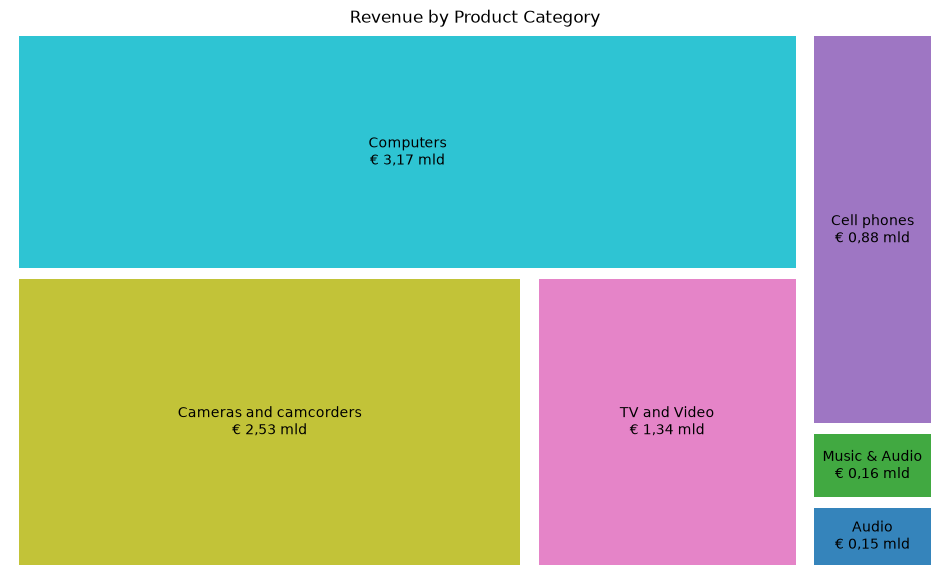

In [94]:
#Chart

#Kleuren van treemap
colors = plt.get_cmap("tab10")(
    np.linspace(0, 1, len(revenuebyproduct))
)

# Labels maken
labels = []

#Loop die de omschrijvingen van productcategorieën toevoegd en aanpast indien dit "Music, Movies and Audio Books" betreft, vanwege lengte/
for row in revenuebyproduct.itertuples():
    category = row.ProductCategory

    if category == "Music, Movies and Audio Books":
        category = "Music & Audio"

    revenue = f"€ {row.revenue / 1e9:.2f}".replace(".", ",")

    labels.append(f"{category}\n{revenue} mld")

#Figuur maken met behulp van matplotlib.
fig, ax = plt.subplots(figsize=(12, 7))

#Treechart maken.
squarify.plot(
    sizes=revenuebyproduct["revenue"],
    label=labels,
    color=colors,
    alpha=0.9,
    pad=True,
    text_kwargs={"fontsize": 10},
    ax=ax
)
#X-axis omdraaien om Tree chart in PowerBI zoveel mogelijk te reproduceren.
ax.invert_xaxis()
plt.axis("off")
plt.title("Revenue by Product Category")
plt.show()

### 2.2.3 Revenue Change vs previous year in % - PPM-04

In [95]:
#Dataframe

#Sales mergen met product data en productcategory data.
revenue_change =( sales_df.merge(product_df,
                                    on="ProductKey", 
                                    how="left")
                                    .merge(productcat_df,
                                    on="ProductSubcategoryKey",
                                    how="left")
)

#Kolommen toevoegen met year en month.
revenue_change["Year"] = revenue_change["Date"].dt.year
revenue_change["Month"] = revenue_change["Date"].dt.month


#Measures voor huidig en voorgaand jaar.
#De grafiek dient altijd het laatste jaar te weergeven dat geselecteerd is.
revenue_change_current = revenue_change["Year"].max()
revenue_change_previous = revenue_change_current - 1

#Omzet per productcategorie en jaar
revenue_by_category = (
    revenue_change
    .groupby(["ProductCategory", "Year"])["SalesAmountRet"]
    .sum()
    .unstack("Year")
)

# Procentuele omzetverandering per categorie
# Indien er geen waarden is om door te delen geeft de grafiek "nan"
revenue_by_category["ChangePct"] = (
    (
        revenue_by_category[revenue_change_current] -
        revenue_by_category[revenue_change_previous]
    )
    / revenue_by_category[revenue_change_previous].replace(0, float("nan"))
) * 100

#Dataframe voor de chart.
chart_df = (
    revenue_by_category
    .reset_index()
    .dropna(subset=["ChangePct"])
    .sort_values("ChangePct", ascending=False)
)


In [96]:
#Chart

#Vertical bar chart maken.
fig = px.bar(
    chart_df,
    x="ProductCategory",
    y="ChangePct",
    orientation="v",
    color="ChangePct",
    #Kleurschaal van groen naar rood.
    color_continuous_scale="RdYlGn",
    color_continuous_midpoint=0,
    text="ChangePct",
    #Titel past zich aan op basis van waarde van laatste en voorgaand jaar.
    title=f"Revenue Change by Product Category ({revenue_change_current} vs {revenue_change_previous})"
)

#Y-as opmaken.
fig.update_yaxes(
    ticksuffix="%",
    tickformat=".0f",
    range=[-40, 40],
    showgrid=True,
    gridcolor="rgba(0,0,0,0.08)",
)

#Waarden bij balk opmaken.
fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    cliponaxis=False
)

#Grafiek opmaak.
fig.update_layout(
    template="plotly_white",
    yaxis_title="Revenue Change (%)",
    xaxis_title=None,
    bargap=0.25,
    margin=dict(t=80, b=80, l=60, r=40),
    separators=",.",
    coloraxis_showscale=False
)

fig.show()

### 2.2.4 Top 10 products by revenue - PPM-02

In [97]:
#Dataframe

# Sales mergen met product en productcategory.
topproducts = (
    sales_df
    .merge(product_df, on="ProductKey", how="left")
    .merge(productcat_df, on="ProductSubcategoryKey", how="left")
)

# Jaar bepalen.
topproducts["Year"] = pd.to_datetime(topproducts["Date"]).dt.year

current_year = topproducts["Year"].max()
previous_year = current_year - 1

# Omzet en afzet per product in het huidige jaar.
current = (
    topproducts.loc[topproducts["Year"] == current_year]
    .groupby("ProductNameNoColor")
    .agg(
        Revenue=("SalesAmountRet", "sum"),
        SalesQuantity=("SalesQuantity", "sum")
    )
)

# Afzet per product in het voorgaande jaar.
previous = (
    topproducts.loc[topproducts["Year"] == previous_year]
    .groupby("ProductNameNoColor")
    .agg(SalesQuantityPY=("SalesQuantity", "sum"))
)

# Huidig en voorgaand jaar samenvoegen.
top10 = current.join(previous, how="left")
top10["SalesQuantityPY"] = top10["SalesQuantityPY"].fillna(0)

# Absolute verandering in verkochte aantallen.
top10["SalesQuantityChange"] = (
    top10["SalesQuantity"] - top10["SalesQuantityPY"]
)

# Top 10 selecteren op omzet.
top10 = (
    top10
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)


In [98]:
#Chart

# Tabel maken.
fig = go.Figure(data=[
    go.Table(
        header=dict(
            values=[
                "Product",
                f"Revenue {current_year}",
                f"Sales quantity {previous_year}",
                "Sales quantity change"
            ],
            fill_color="#DCE6F1",
            align=["left", "right", "right", "right"]
        ),
        cells=dict(
            values=[
                top10["ProductNameNoColor"],
                top10["Revenue"].map(
                    lambda x: f"€ {x:,.0f}".replace(",", ".")
                ),
                top10["SalesQuantityPY"].map(
                    lambda x: f"{x:,.0f}".replace(",", ".")
                ),
                top10["SalesQuantityChange"].map(
                lambda x: f"{x:+,.0f}".replace(",", ".")
                ), 
            ],
            align=["left", "right", "right", "right"],
            height=30
        )
    )
])

fig.update_layout(
    title=f"Top 10 Products by Revenue — {current_year}",
    height=450
)

fig.show()

### 2.2.5 Cost by manufacturer - PPM-05

In [99]:
#Dataframe

#Sales mergen met product en productcategory data.
costbymanufacturer =(sales_df.merge(product_df,
                                    on="ProductKey", 
                                    how="left")
                                    .merge(productcat_df,
                                    on="ProductSubcategoryKey",
                                    how="left"))

#Dataframe aggregeren op producent en kosten.
costbymanufacturer = costbymanufacturer.groupby("Manufacturer")["TotalCostRet"].sum().reset_index().sort_values(by="TotalCostRet", ascending=False)

In [100]:
#Chart

#Pie chart maken
fig = px.pie(
    costbymanufacturer,
    values="TotalCostRet",
    names="Manufacturer",
    title="Cost by manufacturer"
)
#Hoogte en breedte van chart en komma als decimaal scheidingsteken instellen.
fig.update_layout(
    height=450,
    width=800,
    separators=",."
)

#Labels instellen als 
fig.update_traces(
    textposition="outside",
    texttemplate="%{label}: %{percent:.1%}",
    showlegend=False,
)

fig.show()

### 2.2.5 Gross margin versus sales quantity PPM-03

In [101]:
#Dataframe

#Sales mergen met product en productcategory data.
grossmarginplot =( sales_df.merge(product_df,
                                    on="ProductKey", 
                                    how="left")
                                    .merge(productcat_df,
                                    on="ProductSubcategoryKey",
                                    how="left"))

#Revenue en gross margin toevoegen aan dataframe.
grossmarginplot["Revenue"] = grossmarginplot["SalesAmountRet"]
grossmarginplot["GrossMargin"] = grossmarginplot["Revenue"] - grossmarginplot["TotalCostRet"]

#Dataframe aggregeren op productsubcateogrieën met revenue, gross margin en sales quantity.
grossmarginplot = grossmarginplot.groupby("ProductSubcategory").agg(Revenue=("Revenue","sum"),
                                                                    GrossMargin=("GrossMargin","sum"),
                                                                    SalesQuantity=("SalesQuantity","sum")).reset_index()

#Gross margin uitgedrukt als percentage toevoegen aan dataframe.
grossmarginplot["GrossMarginPct"] = grossmarginplot["GrossMargin"]/grossmarginplot["Revenue"]*100



In [102]:
# Chart

#Scatterplot maken.
fig = px.scatter(
    grossmarginplot,
    x="SalesQuantity",
    y="GrossMarginPct",
    color="ProductSubcategory",
    title="Gross margin versus sales quantity",
    size="Revenue",
    custom_data=["ProductSubcategory", "Revenue"]
)

#Layout van grafiek aanpassen.
fig.update_layout(
    xaxis_title="Sales Quantity",
    yaxis_title="Gross margin %",
    height=450,
    width=1000,
    separators=",."
)

fig.update_xaxes(tickformat=",.0f")
fig.update_yaxes(tickformat=",.0f")

#Bijschrift gegevens bij hover over aanpassen.
fig.update_traces(
    hovertemplate=(
        "Product: %{customdata[0]}<br>"
        "Sales Quantity: %{x:,.0f}<br>"
        "Gross Margin: %{y:.1f}%<br>"
        "Revenue: €%{customdata[1]:,.2f}"
        "<extra></extra>"
    ),
    showlegend=False
)

fig.show()

### 2.2.6 Dashboard

In [103]:
# Opbouwen van dataframe voor het Product Portfolio Dashboard
# Eerst de gebruikte dimensies mergen met de salesdata.
portfolio_dashboard_df = (
    sales_df
    .merge(
        channel_df,
        on="ChannelKey",
        how="left"
    )
    .merge(
        product_df,
        on="ProductKey",
        how="left"
    )
    .merge(
        productcat_df,
        on="ProductSubcategoryKey",
        how="left"
    )
)

# Jaar en maand toevoegen voor de slicers en jaarvergelijking.
portfolio_dashboard_df["Year"] = portfolio_dashboard_df["Date"].dt.year
portfolio_dashboard_df["Month"] = portfolio_dashboard_df["Date"].dt.month


In [104]:
# Slicers opbouwen

# Year slicer
portfolio_year_options = sorted(
    portfolio_dashboard_df["Year"].unique()
)

portfolio_year_dropdown = dcc.Dropdown(
    id="portfolio-year-filter",
    options=[
        {"label": str(year), "value": year}
        for year in portfolio_year_options
    ],
    placeholder="Select year",
    multi=True
)

# Month slicer
portfolio_month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

portfolio_month_options = sorted(
    portfolio_dashboard_df["Month"].unique()
)

portfolio_month_dropdown = dcc.Dropdown(
    id="portfolio-month-filter",
    options=[
        {
            "label": portfolio_month_names[month - 1],
            "value": int(month)
        }
        for month in portfolio_month_options
    ],
    placeholder="Select month(s)",
    multi=True
)

# Channel slicer
portfolio_channel_options = (
    portfolio_dashboard_df["ChannelName"]
    .dropna()
    .unique()
)

portfolio_channel_list = dcc.Checklist(
    id="portfolio-channel-filter",
    options=[
        {"label": channel, "value": channel}
        for channel in portfolio_channel_options
    ],
    value=[]
)

# Product category slicer
portfolio_category_options = (
    portfolio_dashboard_df["ProductCategory"]
    .dropna()
    .unique()
)

portfolio_category_list = dcc.Checklist(
    id="portfolio-category-filter",
    options=[
        {"label": category, "value": category}
        for category in portfolio_category_options
    ],
    value=[]
)

# Product subcategory slicer
portfolio_subcategory_options = sorted(
    portfolio_dashboard_df["ProductSubcategory"]
    .dropna()
    .unique()
)

portfolio_subcategory_dropdown = dcc.Dropdown(
    id="portfolio-subcategory-filter",
    options=[
        {"label": subcategory, "value": subcategory}
        for subcategory in portfolio_subcategory_options
    ],
    placeholder="Select product subcategory",
    multi=True
)

# Manufacturer slicer
portfolio_manufacturer_options = sorted(
    portfolio_dashboard_df["Manufacturer"]
    .dropna()
    .unique()
)

portfolio_manufacturer_dropdown = dcc.Dropdown(
    id="portfolio-manufacturer-filter",
    options=[
        {"label": manufacturer, "value": manufacturer}
        for manufacturer in portfolio_manufacturer_options
    ],
    placeholder="Select manufacturer",
    multi=True
)



In [105]:
# Dashboard 
# App initialiseren
portfoliodashboard = dash.Dash(__name__)

# Dashboard layout

portfoliodashboard.layout = html.Div([

    # Dashboardtitel
   
    html.H2(
        "Product Portfolio Dashboard",
        style={
            "textAlign": "center",
            "backgroundColor": "white",
            "margin": "0",
            "padding": "20px",
            "width": "100%",
            "boxSizing": "border-box",
            "fontSize": "32px"
        }
    ),

   
    # Hoofdcontainer: filters links, dashboard rechts
    
    html.Div([

       
        # Linkerkolom: filters
       
        html.Div([

            html.H4("Filters"),

            html.Label("Year"),
            portfolio_year_dropdown,

            html.Label("Month"),
            portfolio_month_dropdown,

            html.Label("Sales channel"),
            portfolio_channel_list,

            html.Label("Product category"),
            portfolio_category_list,

            html.Label("Product subcategory"),
            portfolio_subcategory_dropdown,

            html.Label("Manufacturer"),
            portfolio_manufacturer_dropdown

        ],
        style={
            "width": "250px",
            "flex": "0 0 250px",
            "padding": "20px",
            "backgroundColor": "white",
            "boxSizing": "border-box",
            "minWidth": "0"
        }),

       
        # Rechterkolom: dashboard
    
        html.Div([

            
            # KPI-rij: vier KPI's
            html.Div([

                # KPI 1: Revenue
                html.Div(
                    dcc.Graph(
                        id="portfolio-revenue-kpi",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "300px"
                        }
                    ),
                    style={
                        "flex": "1 1 220px",
                        "minWidth": "0"
                    }
                ),

                # KPI 2: Sales Quantity
                html.Div(
                    dcc.Graph(
                        id="portfolio-sales-quantity-kpi",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "300px"
                        }
                    ),
                    style={
                        "flex": "1 1 220px",
                        "minWidth": "0"
                    }
                ),

                # KPI 3: Gross Margin
                html.Div(
                    dcc.Graph(
                        id="portfolio-gross-margin-kpi",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "300px"
                        }
                    ),
                    style={
                        "flex": "1 1 220px",
                        "minWidth": "0"
                    }
                ),

                # KPI 4: Gross Margin %
                html.Div(
                    dcc.Graph(
                        id="portfolio-gross-margin-pct-kpi",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "300px"
                        }
                    ),
                    style={
                        "flex": "1 1 220px",
                        "minWidth": "0"
                    }
                )

            ],
            style={
                "display": "flex",
                "flexWrap": "wrap",
                "width": "100%",
                "gap": "10px",
                "alignItems": "stretch"
            }),

            # Eerste grafiekrij: twee visualisaties
            html.Div([

                # Revenue by Product Category
                html.Div(
                    dcc.Graph(
                        id="portfolio-revenue-by-category",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "450px"
                        }
                    ),
                    style={
                        "flex": "1 1 400px",
                        "minWidth": "0"
                    }
                ),

                # Revenue Change
                html.Div(
                    dcc.Graph(
                        id="portfolio-revenue-change",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "450px"
                        }
                    ),
                    style={
                        "flex": "1 1 400px",
                        "minWidth": "0"
                    }
                )

            ],
            style={
                "display": "flex",
                "flexWrap": "wrap",
                "width": "100%",
                "gap": "10px",
                "alignItems": "stretch"
            }),

            # Tweede grafiekrij: drie visualisaties
            html.Div([

                # Top 10 Products
                html.Div(
                    dcc.Graph(
                        id="portfolio-top-products",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "450px"
                        }
                    ),
                    style={
                        "flex": "1 1 300px",
                        "minWidth": "0"
                    }
                ),

                # Cost by Manufacturer
                html.Div(
                    dcc.Graph(
                        id="portfolio-cost-by-manufacturer",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "450px"
                        }
                    ),
                    style={
                        "flex": "1 1 300px",
                        "minWidth": "0"
                    }
                ),

                # Gross Margin versus Sales Quantity
                html.Div(
                    dcc.Graph(
                        id="portfolio-margin-vs-quantity",
                        responsive=True,
                        style={
                            "width": "100%",
                            "height": "450px"
                        }
                    ),
                    style={
                        "flex": "1 1 300px",
                        "minWidth": "0"
                    }
                )

            ],
            style={
                "display": "flex",
                "flexWrap": "wrap",
                "width": "100%",
                "gap": "10px",
                "alignItems": "stretch"
            })

        ],
        style={
            "flex": "1 1 0",
            "minWidth": "0",
            "padding": "15px",
            "boxSizing": "border-box",
            "display": "flex",
            "flexDirection": "column",
            "gap": "15px",
            "backgroundColor": "#F5F7FB"
        })

    ],
    style={
        "display": "flex",
        "flexDirection": "row",
        "width": "100%",
        "alignItems": "flex-start"
    })

],
style={
    "width": "100%",
    "minHeight": "100vh",
    "margin": "0",
    "padding": "0",
    "boxSizing": "border-box",
    "backgroundColor": "#F5F7FB"
})


@portfoliodashboard.callback(
    Output("portfolio-revenue-kpi", "figure"),
    Output("portfolio-sales-quantity-kpi", "figure"),
    Output("portfolio-gross-margin-kpi", "figure"),
    Output("portfolio-gross-margin-pct-kpi", "figure"),
    Output("portfolio-revenue-by-category", "figure"),
    Output("portfolio-revenue-change", "figure"),
    Output("portfolio-top-products", "figure"),
    Output("portfolio-cost-by-manufacturer", "figure"),
    Output("portfolio-margin-vs-quantity", "figure"),
    Input("portfolio-year-filter", "value"),
    Input("portfolio-month-filter", "value"),
    Input("portfolio-channel-filter", "value"),
    Input("portfolio-category-filter", "value"),
    Input("portfolio-subcategory-filter", "value"),
    Input("portfolio-manufacturer-filter", "value")
)

# Functie die het dashboard update op basis van de geselecteerde filters.
def update_portfolio_dashboard(
    selected_years,
    selected_months,
    selected_channels,
    selected_categories,
    selected_subcategories,
    selected_manufacturers
):
    # Kopie van dataframe maken om de filters toe te passen.
    df_base = portfolio_dashboard_df.copy()

    # Filters toepassen.
    if selected_months:
        df_base = df_base[
            df_base["Month"].isin(selected_months)
        ]

    if selected_channels:
        df_base = df_base[
            df_base["ChannelName"].isin(selected_channels)
        ]

    if selected_categories:
        df_base = df_base[
            df_base["ProductCategory"].isin(selected_categories)
        ]

    if selected_subcategories:
        df_base = df_base[
            df_base["ProductSubcategory"].isin(selected_subcategories)
        ]

    if selected_manufacturers:
        df_base = df_base[
            df_base["Manufacturer"].isin(selected_manufacturers)
        ]

    # Jaarfilter toepassen op de visuals.
    if selected_years:
        df = df_base[
            df_base["Year"].isin(selected_years)
        ]
        current_year = max(selected_years)
    else:
        df = df_base
        current_year = portfolio_dashboard_df["Year"].max()

    # Voorgaand jaar bepalen.
    previous_year = current_year - 1

    # Data voor huidig en voorgaand jaar.
    df_kpi_current = df_base[
        df_base["Year"] == current_year
    ]

    df_kpi_previous = df_base[
        df_base["Year"] == previous_year
    ]

    has_previous_year = not df_kpi_previous.empty

    # KPI-measures huidig jaar.
    revenue_current = df_kpi_current["SalesAmountRet"].sum()
    sales_quantity_current = df_kpi_current["SalesQuantity"].sum()
    total_cost_current = df_kpi_current["TotalCostRet"].sum()
    gross_margin_current = revenue_current - total_cost_current

    gross_margin_pct_current = (
        gross_margin_current / revenue_current * 100
        if revenue_current != 0
        else 0
    )

    # KPI-measures voorgaand jaar.
    revenue_previous = df_kpi_previous["SalesAmountRet"].sum()
    sales_quantity_previous = df_kpi_previous["SalesQuantity"].sum()
    total_cost_previous = df_kpi_previous["TotalCostRet"].sum()
    gross_margin_previous = revenue_previous - total_cost_previous

    gross_margin_pct_previous = (
        gross_margin_previous / revenue_previous * 100
        if revenue_previous != 0
        else 0
    )

    # KPI Revenue
    KPIrevenue = go.Figure(
        go.Indicator(
            mode="number+delta" if has_previous_year and revenue_previous != 0 else "number",
            value=revenue_current,
            title={
                "text": (
                    f"Revenue<br>"
                    f"<span style='font-size:0.7em'>Current year: {current_year}</span>"
                )
            },
            number={
                "prefix": "€",
                "valueformat": ",.0f"
            },
            delta={
                "reference": revenue_previous,
                "relative": True,
                "valueformat": ".1%"
            }
        )
    )

    KPIrevenue.update_layout(
        height=300,
        template="plotly_white",
        separators=",."
    )

    # KPI Sales Quantity
    KPIsalesquantity = go.Figure(
        go.Indicator(
            mode="number+delta" if has_previous_year and sales_quantity_previous != 0 else "number",
            value=sales_quantity_current,
            title={
                "text": (
                    f"Sales quantity<br>"
                    f"<span style='font-size:0.7em'>Current year: {current_year}</span>"
                )
            },
            number={
                "valueformat": ",.0f"
            },
            delta={
                "reference": sales_quantity_previous,
                "relative": True,
                "valueformat": ".1%"
            }
        )
    )

    KPIsalesquantity.update_layout(
        height=300,
        template="plotly_white",
        separators=",."
    )

    # KPI Gross Margin
    KPIgrossmargin = go.Figure(
        go.Indicator(
            mode="number+delta" if has_previous_year and gross_margin_previous != 0 else "number",
            value=gross_margin_current,
            title={
                "text": (
                    f"Gross margin<br>"
                    f"<span style='font-size:0.7em'>Current year: {current_year}</span>"
                )
            },
            number={
                "prefix": "€",
                "valueformat": ",.0f"
            },
            delta={
                "reference": gross_margin_previous,
                "relative": True,
                "valueformat": ".1%"
            }
        )
    )

    KPIgrossmargin.update_layout(
        height=300,
        template="plotly_white",
        separators=",."
    )

    # KPI Gross Margin %
    KPIgrossmarginpct = go.Figure(
        go.Indicator(
            mode="number+delta" if has_previous_year else "number",
            value=gross_margin_pct_current,
            title={
                "text": (
                    f"Gross margin %<br>"
                    f"<span style='font-size:0.7em'>Current year: {current_year}</span>"
                )
            },
            number={
                "suffix": "%",
                "valueformat": ".1f"
            },
            delta={
                "reference": gross_margin_pct_previous,
                "relative": False,
                "valueformat": ".1f",
                "suffix": " pp"
            }
        )
    )

    KPIgrossmarginpct.update_layout(
        height=300,
        template="plotly_white",
        separators=",."
    )

    # Aggregatie voor Revenue by Product Category.
    category_revenue = (
        df
        .groupby("ProductCategory", as_index=False)
        .agg(
            Revenue=("SalesAmountRet", "sum")
        )
        .sort_values("Revenue", ascending=False)
    )

    # Aggregatie voor Revenue Change versus Previous Year.
    revenue_current_category = (
        df_kpi_current
        .groupby("ProductCategory")["SalesAmountRet"]
        .sum()
        .rename("RevenueCurrent")
    )

    revenue_previous_category = (
        df_kpi_previous
        .groupby("ProductCategory")["SalesAmountRet"]
        .sum()
        .rename("RevenuePrevious")
    )

    revenue_change = (
        pd.concat(
            [
                revenue_current_category,
                revenue_previous_category
            ],
            axis=1
        )
        .fillna(0)
        .reset_index()
    )

    revenue_change["ChangePct"] = (
        (
            revenue_change["RevenueCurrent"] -
            revenue_change["RevenuePrevious"]
        )
        /
        revenue_change["RevenuePrevious"].replace(0, np.nan)
    ) * 100

    revenue_change = (
        revenue_change
        .dropna(subset=["ChangePct"])
        .sort_values("ChangePct", ascending=False)
    )

    # Aggregatie voor Top 10 Products: huidig jaar.
    current_products = (
        df_kpi_current
        .groupby("ProductNameNoColor")
        .agg(
            Revenue=("SalesAmountRet", "sum"),
            SalesQuantity=("SalesQuantity", "sum")
        )
    )

    # Afzet per product in het voorgaande jaar.
    previous_products = (
        df_kpi_previous
        .groupby("ProductNameNoColor")
        .agg(SalesQuantityPY=("SalesQuantity", "sum"))
    )

    # Huidig en voorgaand jaar samenvoegen.
    top_products = current_products.join(
        previous_products,
        how="left"
    )

    top_products["SalesQuantityPY"] = (
        top_products["SalesQuantityPY"].fillna(0)
    )

    # Absolute verandering in verkochte aantallen.
    top_products["SalesQuantityChange"] = (
        top_products["SalesQuantity"]
        - top_products["SalesQuantityPY"]
    )

    # Top 10 selecteren op omzet van het huidige jaar.
    top_products = (
        top_products
        .sort_values("Revenue", ascending=False)
        .head(10)
        .reset_index()
    )

    # Aggregatie voor Cost by Manufacturer.
    manufacturer_cost = (
        df
        .groupby("Manufacturer", as_index=False)
        .agg(
            TotalCost=("TotalCostRet", "sum")
        )
        .sort_values("TotalCost", ascending=False)
    )

    # Aggregatie voor Gross Margin versus Sales Quantity.
    gross_margin_plot = df.copy()
    gross_margin_plot["Revenue"] = (
        gross_margin_plot["SalesAmountRet"]
    )
    gross_margin_plot["GrossMargin"] = (
        gross_margin_plot["Revenue"] -
        gross_margin_plot["TotalCostRet"]
    )

    gross_margin_plot = (
        gross_margin_plot
        .groupby("ProductSubcategory", as_index=False)
        .agg(
            Revenue=("Revenue", "sum"),
            GrossMargin=("GrossMargin", "sum"),
            SalesQuantity=("SalesQuantity", "sum")
        )
    )

    gross_margin_plot["GrossMarginPct"] = (
        gross_margin_plot["GrossMargin"] /
        gross_margin_plot["Revenue"] * 100
    )

    # Treemap Revenue by Product Category.
    RevenueByProductCategory = px.treemap(
        category_revenue,
        path=["ProductCategory"],
        values="Revenue",
        color="ProductCategory",
        title="Revenue by product category"
    )

    RevenueByProductCategory.update_traces(
        texttemplate=(
            "<b>%{label}</b><br>"
            "€%{value:,.0f}"
        ),
        hovertemplate=(
            "%{label}<br>"
            "Revenue: €%{value:,.2f}"
            "<extra></extra>"
        )
    )

    RevenueByProductCategory.update_layout(
        height=450,
        separators=",."
    )

    # Barchart Revenue Change versus Previous Year.
    RevenueChange = px.bar(
        revenue_change,
        x="ProductCategory",
        y="ChangePct",
        color="ChangePct",
        color_continuous_scale="RdYlGn",
        color_continuous_midpoint=0,
        text="ChangePct",
        title=(
            f"Revenue change by product category "
            f"({current_year} vs {previous_year})"
        )
    )

    RevenueChange.update_traces(
        texttemplate="%{text:.1f}%",
        textposition="outside",
        cliponaxis=False
    )

    RevenueChange.update_yaxes(
        ticksuffix="%",
        tickformat=".0f"
    )

    RevenueChange.update_layout(
        template="plotly_white",
        height=450,
        coloraxis_showscale=False,
        xaxis_title=None,
        yaxis_title="Revenue change (%)",
        separators=",."
    )

    # Tabel Top 10 Products by Revenue.
    TopProducts = go.Figure(data=[
        go.Table(
            header=dict(
                values=[
                    "Product",
                    f"Revenue {current_year}",
                    f"Sales quantity {previous_year}",
                    "Sales quantity change"
                ],
                fill_color="#DCE6F1",
                align=["left", "right", "right", "right"]
            ),
            cells=dict(
                values=[
                    top_products["ProductNameNoColor"],
                    top_products["Revenue"].map(
                        lambda x: f"€ {x:,.0f}".replace(",", ".")
                    ),
                    top_products["SalesQuantityPY"].map(
                        lambda x: f"{x:,.0f}".replace(",", ".")
                    ),
                    top_products["SalesQuantityChange"].map(
                        lambda x: f"{x:+,.0f}".replace(",", ".")
                    )
                ],
                align=["left", "right", "right", "right"],
                height=30
            )
        )
    ])

    TopProducts.update_layout(
        title=f"Top 10 products by revenue — {current_year}",
        height=450
    )

    TopProducts.update_layout(
        title="Top 10 products by revenue",
        height=450
    )

    # Piechart Cost by Manufacturer.
    CostByManufacturer = px.pie(
        manufacturer_cost,
        values="TotalCost",
        names="Manufacturer",
        title="Cost by manufacturer"
    )

    CostByManufacturer.update_traces(
        textposition="outside",
        texttemplate="%{label}: %{percent:.1%}",
        showlegend=False
    )

    CostByManufacturer.update_layout(
        height=450,
        separators=",."
    )

    # Scatterplot Gross Margin versus Sales Quantity.
    GrossMarginVsSalesQuantity = px.scatter(
        gross_margin_plot,
        x="SalesQuantity",
        y="GrossMarginPct",
        color="ProductSubcategory",
        size="Revenue",
        custom_data=[
            "ProductSubcategory",
            "Revenue"
        ],
        title="Gross margin versus sales quantity"
    )

    GrossMarginVsSalesQuantity.update_traces(
        hovertemplate=(
            "Product: %{customdata[0]}<br>"
            "Sales Quantity: %{x:,.0f}<br>"
            "Gross Margin: %{y:.1f}%<br>"
            "Revenue: €%{customdata[1]:,.2f}"
            "<extra></extra>"
        ),
        showlegend=False
    )

    GrossMarginVsSalesQuantity.update_xaxes(
        title="Sales Quantity",
        tickformat=",.0f"
    )

    GrossMarginVsSalesQuantity.update_yaxes(
        title="Gross margin %",
        ticksuffix="%",
        tickformat=".1f"
    )

    GrossMarginVsSalesQuantity.update_layout(
        height=450,
        separators=",."
    )

    return (
        KPIrevenue,
        KPIsalesquantity,
        KPIgrossmargin,
        KPIgrossmarginpct,
        RevenueByProductCategory,
        RevenueChange,
        TopProducts,
        CostByManufacturer,
        GrossMarginVsSalesQuantity
    )


portfoliodashboard.run(debug=True, port=8051)